# Experiment 8: Semantic Similarity Analysis Tool using WordNet and Pre-trained Word Embeddings

### Problem Statement:
Develop a semantic similarity analysis tool using WordNet and pre-trained word embeddings to measure semantic relationships between words, phrases, and documents.


In [1]:
import nltk
from nltk.corpus import wordnet as wn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import spacy
from gensim.models import Word2Vec

# Ensure WordNet is ready
nltk.download('wordnet', quiet=True)
nltk.download('omw-1.4', quiet=True)

nlp = spacy.load("en_core_web_sm")
print("WordNet and vector modeling libraries ready.")


WordNet and vector modeling libraries ready.


In [2]:
word_pairs = [
    ("car", "automobile", "Synonyms"),
    ("journey", "voyage", "Synonyms"),
    ("doctor", "hospital", "Related Concept"),
    ("cat", "dog", "Coordinate Terms"),
    ("hot", "cold", "Antonyms"),
    ("car", "philosophy", "Unrelated")
]

sim_results = []
for w1, w2, relation in word_pairs:
    syns1 = wn.synsets(w1)
    syns2 = wn.synsets(w2)
    
    if syns1 and syns2:
        s1 = syns1[0]
        s2 = syns2[0]
        
        path_sim = s1.path_similarity(s2) or 0.0
        wup_sim = s1.wup_similarity(s2) or 0.0
        
        # LCH is valid when both synsets share identical POS
        if s1.pos() == s2.pos():
            lch_sim = s1.lch_similarity(s2) or 0.0
        else:
            lch_sim = 0.0
            
        sim_results.append({
            "Word 1": w1,
            "Word 2": w2,
            "Relation": relation,
            "Synset 1": s1.name(),
            "Synset 2": s2.name(),
            "Path Sim": round(path_sim, 3),
            "Wu-Palmer Sim": round(wup_sim, 3),
            "Leacock-Chodorow Sim": round(lch_sim, 3)
        })

df_wordnet_sim = pd.DataFrame(sim_results)
print("--- WordNet Semantic Similarity Comparison Table ---")
print(df_wordnet_sim.to_string(index=False))


--- WordNet Semantic Similarity Comparison Table ---
 Word 1     Word 2         Relation     Synset 1        Synset 2  Path Sim  Wu-Palmer Sim  Leacock-Chodorow Sim
    car automobile         Synonyms     car.n.01        car.n.01     1.000          1.000                 3.638
journey     voyage         Synonyms journey.n.01 ocean_trip.n.01     0.250          0.857                 2.251
 doctor   hospital  Related Concept  doctor.n.01   hospital.n.01     0.071          0.381                 0.999
    cat        dog Coordinate Terms     cat.n.01        dog.n.01     0.200          0.857                 2.028
    hot       cold         Antonyms     hot.a.01       cold.n.01     0.071          0.133                 0.000
    car philosophy        Unrelated     car.n.01   doctrine.n.01     0.059          0.111                 0.804


In [3]:
training_corpus = [
    ["king", "monarch", "ruler", "palace", "throne", "crown", "empire", "man"],
    ["queen", "monarch", "ruler", "palace", "throne", "crown", "empire", "woman"],
    ["doctor", "hospital", "physician", "patient", "medicine", "nurse", "clinic"],
    ["engineer", "software", "computer", "developer", "algorithm", "code", "system"],
    ["car", "automobile", "vehicle", "engine", "highway", "driver", "transport"],
    ["apple", "fruit", "orange", "banana", "sweet", "orchard", "harvest"],
    ["deep", "learning", "neural", "networks", "machine", "intelligence", "models"],
    ["artificial", "intelligence", "data", "science", "algorithms", "models", "learning"]
]

w2v = Word2Vec(sentences=training_corpus, vector_size=64, window=4, min_count=1, workers=2, epochs=250, seed=42)

# 1. Pairwise Cosine Similarities
print("--- Word2Vec Cosine Similarities ---")
pairs_to_test = [("king", "queen"), ("doctor", "physician"), ("car", "automobile"), ("apple", "computer")]
for w1, w2 in pairs_to_test:
    sim = w2v.wv.similarity(w1, w2)
    print(f"Cosine Similarity ({w1}, {w2}) = {sim:.4f}")

# 2. Vector Analogy: king - man + woman = ?
analogy_result = w2v.wv.most_similar(positive=["king", "woman"], negative=["man"], topn=3)
print(f"\n--- Word Analogy: 'king' - 'man' + 'woman' ---")
for candidate, score in analogy_result:
    print(f"  -> {candidate:<12} (Score: {score:.4f})")

# 3. Top Semantic Neighbors
query = "artificial"
neighbors = w2v.wv.most_similar(query, topn=4)
print(f"\n--- Top Semantic Neighbors for '{query}' ---")
for word, score in neighbors:
    print(f"  {word:<15} : {score:.4f}")


--- Word2Vec Cosine Similarities ---
Cosine Similarity (king, queen) = 0.1009
Cosine Similarity (doctor, physician) = 0.2917
Cosine Similarity (car, automobile) = 0.4227
Cosine Similarity (apple, computer) = 0.2305

--- Word Analogy: 'king' - 'man' + 'woman' ---
  -> apple        (Score: 0.1997)
  -> throne       (Score: 0.1686)
  -> clinic       (Score: 0.1217)

--- Top Semantic Neighbors for 'artificial' ---
  intelligence    : 0.4244
  medicine        : 0.4041
  orchard         : 0.3421
  engine          : 0.3383


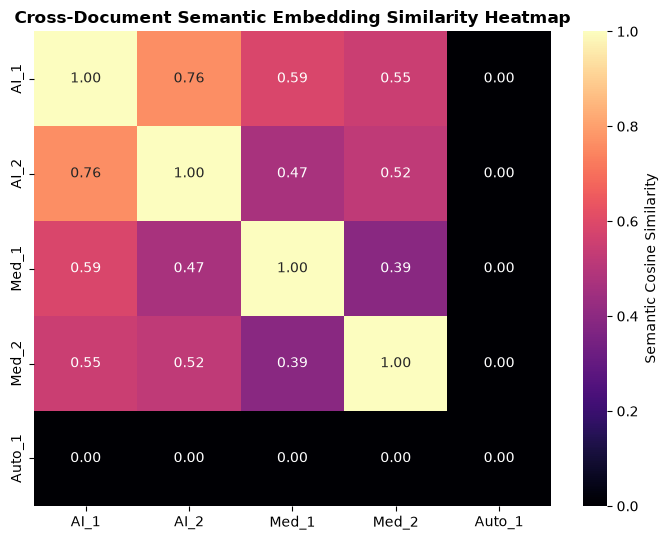

In [4]:
documents = {
    "AI_1": "Artificial intelligence algorithms and neural networks learn models from data.",
    "AI_2": "Deep learning and machine intelligence systems optimize algorithmic representations.",
    "Med_1": "Doctors, physicians, and nurses treat patients with specialized medicine in clinics.",
    "Med_2": "Hospitals and healthcare clinics provide medical care, surgery, and patient treatments.",
    "Auto_1": "Modern automobiles and electric vehicles utilize advanced engines and automated highways."
}

def get_doc_vector(text, model):
    tokens = [w for w in text.lower().replace('.', '').replace(',', '').split() if w in model.wv]
    if not tokens:
        return np.zeros(model.vector_size)
    vectors = [model.wv[w] for w in tokens]
    return np.mean(vectors, axis=0)

doc_keys = list(documents.keys())
doc_vectors = [get_doc_vector(documents[k], w2v) for k in doc_keys]

# Compute Pairwise Cosine Similarity Matrix
num_docs = len(doc_keys)
sim_matrix = np.zeros((num_docs, num_docs))

for i in range(num_docs):
    for j in range(num_docs):
        u = doc_vectors[i]
        v = doc_vectors[j]
        norm_prod = np.linalg.norm(u) * np.linalg.norm(v)
        sim_matrix[i, j] = np.dot(u, v) / norm_prod if norm_prod > 0 else 0.0

plt.figure(figsize=(7, 5.5))
sns.heatmap(sim_matrix, annot=True, fmt=".2f", cmap="magma",
            xticklabels=doc_keys, yticklabels=doc_keys, cbar_kws={'label': 'Semantic Cosine Similarity'})
plt.title("Cross-Document Semantic Embedding Similarity Heatmap", fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()
